## Fractal Dimension + k-NN — PLUS Dataset (From Scratch)

### 1 — Import libraries

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


### 2 — Locate genuine and spoofed images

In [9]:
DATASET = Path("Data_FV_Spoofing_WS2025_26/PLUS")

real_dir = DATASET / "real"
spoof_dir = DATASET / "spoof"

real_files = sorted(real_dir.rglob("*.png"))
spoof_files = sorted(spoof_dir.rglob("*.png"))

print("Genuine images:", len(real_files))
print("Spoofed images:", len(spoof_files))

Genuine images: 1800
Spoofed images: 393


## 3- Balanced dataset

In [10]:
matched_pairs = []

for spoof_path in spoof_files:
    subject_id = spoof_path.parent.name
    real_path = real_dir / subject_id / spoof_path.name

    if real_path.is_file():
        matched_pairs.append((real_path, spoof_path))

print("Matched pairs:", len(matched_pairs))
print("Total selected images:", len(matched_pairs) * 2)

subject_ids = sorted({
    real_path.parent.name
    for real_path, spoof_path in matched_pairs
})

print("Unique subjects:", len(subject_ids))
print("Subjects:", subject_ids)

Matched pairs: 393
Total selected images: 786
Unique subjects: 22
Subjects: ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010', '013', '015', '043', '046', '047', '048', '052', '053', '054', '055', '056', '057']


## 4 — Create a table of image paths and labels

In [11]:
records = []

for real_path, spoof_path in matched_pairs:
    subject_id = real_path.parent.name

    records.append({
        "path": str(real_path),
        "subject_id": subject_id,
        "label": 0
    })

    records.append({
        "path": str(spoof_path),
        "subject_id": subject_id,
        "label": 1
    })

dataset_df = pd.DataFrame(records)

print("Total samples:", len(dataset_df))
print("\nClass distribution:")
print(dataset_df["label"].value_counts())

print("\nNumber of subjects:")
print(dataset_df["subject_id"].nunique())

display(dataset_df.head())

Total samples: 786

Class distribution:
label
0    393
1    393
Name: count, dtype: int64

Number of subjects:
22


,path,subject_id,label
0,Data_FV_Spoofing_WS2025_26/PLUS/real/001/PLUS-...,001,0
1,Data_FV_Spoofing_WS2025_26/PLUS/spoof/001/PLUS...,001,1
2,Data_FV_Spoofing_WS2025_26/PLUS/real/001/PLUS-...,001,0
3,Data_FV_Spoofing_WS2025_26/PLUS/spoof/001/PLUS...,001,1
4,Data_FV_Spoofing_WS2025_26/PLUS/real/001/PLUS-...,001,0


## 5- Verify

In [12]:
counts = dataset_df.groupby(
    ["subject_id", "label"]
).size().unstack(fill_value=0)

display(counts)

assert (counts[0] == counts[1]).all(), (
    "Genuine and spoofed counts differ for some subjects."
)

assert dataset_df["path"].is_unique

print("Dataset checks passed!")

label,0,1
subject_id,,
001,18,18
002,18,18
003,18,18
004,18,18
005,18,18
006,18,18
007,18,18
008,18,18
009,18,18


Dataset checks passed!


In [13]:
# Save image paths, subject IDs, and labels
dataset_df.to_csv(
    "PLUS_dataset_labels.csv",
    index=False
)

print("Dataset table saved successfully!")

Dataset table saved successfully!


# Fractal Dimension Feature Extraction
## 6 — Box counting Function
What does this function do?
Imagine placing a grid of squares over your finger-vein pattern. It counts how many squares contain part of the pattern.
We repeat that with different box sizes to estimate how the image's patterns scale.

In [14]:
import numpy as np

def box_count(binary_image, box_size):
    """
    Count how many boxes contain at least one
    foreground pixel.
    """

    height, width = binary_image.shape
    count = 0

    for y in range(0, height, box_size):
        for x in range(0, width, box_size):

            block = binary_image[
                y:y + box_size,
                x:x + box_size
            ]

            if np.any(block):
                count += 1

    return count

## 7 — Fractal Dimension Calculation Function
What does this calculate?
For each box size, we count the occupied boxes. We then create a log–log relationship:
$$
D \approx \frac{\Delta \log N(\varepsilon)}
{\Delta \log(1/\varepsilon)}
$$

The estimated slope is your Fractal Dimension.

In [15]:
def fractal_from_binary(binary_image):

    box_sizes = np.array([2, 4, 8, 16, 32])

    counts = np.array([
        box_count(binary_image, size)
        for size in box_sizes
    ])

    valid = counts > 0

    if valid.sum() < 3:
        return np.nan

    x = np.log(1 / box_sizes[valid])
    y = np.log(counts[valid])

    fractal_dimension = np.polyfit(x, y, 1)[0]

    return fractal_dimension

## 8 - Approach 1 — Fractal Dimension using five grayscale thresholds
I first tried extracting Fractal Dimension features using five grayscale thresholds: 60, 90, 120, 150, and 180.

For each threshold, I converted the image into a black-and-white pattern and used box counting to calculate its Fractal Dimension.

This gave me five numerical features for each image.

Why I decided not to use this as my final approach:

The results were very accurate, but when I checked the images more closely, I noticed that genuine and spoofed images had quite different brightness levels.

The average brightness was approximately 74 for genuine images and 108 for spoofed images.

Because I was using fixed brightness thresholds, the features might have been capturing these brightness differences instead of the actual complexity of the finger-vein patterns.

So, although the method worked and produced valid feature vectors, I wanted to try an approach that focused more on the image texture.

In [16]:
import cv2

def extract_fractal_features(image):

    height, width = image.shape

    # Crop 10% from left and right
    cropped = image[
        :,
        int(width * 0.1):int(width * 0.9)
    ]

    # Improve local contrast
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(cropped)

    features = []

    thresholds = [60, 90, 120, 150, 180]

    for threshold in thresholds:

        binary = enhanced < threshold

        fd = fractal_from_binary(binary)

        features.append(fd)

    return np.array(features)

## Test with one genuine and one spoofed image

In [17]:
# Select one image of each class
real_path = dataset_df[
    dataset_df["label"] == 0
]["path"].iloc[0]

spoof_path = dataset_df[
    dataset_df["label"] == 1
]["path"].iloc[0]

real_image = cv2.imread(
    real_path, cv2.IMREAD_GRAYSCALE
)

spoof_image = cv2.imread(
    spoof_path, cv2.IMREAD_GRAYSCALE
)

assert real_image is not None
assert spoof_image is not None

real_features = extract_fractal_features(real_image)
spoof_features = extract_fractal_features(spoof_image)

print("Genuine feature vector:", real_features)
print("Spoofed feature vector:", spoof_features)

Genuine feature vector: [1.64962633 1.8571539  1.91576885 1.95805229 1.97637141]
Spoofed feature vector: [1.56866787 1.76260207 1.87028767 1.92238823 1.95075365]


## Approach 2 - Regional Box Counting with Canny Edge Detection
For my second approach, I divided each image into nine regions using a 3×3 grid.

I used edge detection to find patterns in the image and then calculated the Fractal Dimension separately for each region.

The idea was to measure the complexity of different parts of the finger instead of calculating features from the whole image.

Why this approach had problems:

When I tested it, some regions of the genuine image had almost no detected edges.

For example, regions 1, 2, and 6 had zero edge pixels, while region 4 had only one.

Because there were not enough edges in these regions, the Fractal Dimension calculation returned missing values (NaN) or unreliable values.

The spoofed image had many more detected edges, so the method was not working consistently for both types of images.

I decided to try another method that would not depend entirely on edge detection.

In [18]:
import cv2
import numpy as np

def extract_region_fractal_features(image):
    """
    Extract 9 fractal dimension features using a 3x3 grid.
    """

    # 1. Crop outer image borders
    height, width = image.shape

    cropped = image[
        :,
        int(width * 0.10):int(width * 0.90)
    ]

    # 2. Improve local contrast
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(cropped)

    # 3. Reduce noise
    blurred = cv2.GaussianBlur(
        enhanced, (3, 3), 0
    )

    # 4. Detect texture edges
    edges = cv2.Canny(
        blurred, 30, 100
    )

    # 5. Divide edge image into 3x3 regions
    regions = [
        np.array(region)
        for row in np.array_split(edges, 3, axis=0)
        for region in np.array_split(row, 3, axis=1)
    ]

    # 6. Calculate fractal dimension per region
    features = []

    for region in regions:
        fd = fractal_from_binary(region > 0)
        features.append(fd)

    return np.array(features, dtype=float)

## Test it on your two images

In [19]:
real_region_features = extract_region_fractal_features(
    real_image
)

spoof_region_features = extract_region_fractal_features(
    spoof_image
)

print("Genuine feature vector:")
print(real_region_features)

print("\nSpoofed feature vector:")
print(spoof_region_features)

print("\nVector lengths:")
print(len(real_region_features))
print(len(spoof_region_features))

Genuine feature vector:
[       nan        nan 0.90443941 0.         0.74621614        nan
 1.14919745 1.2577515  1.11290727]

Spoofed feature vector:
[1.35349329 1.49218549 1.22984922 1.47087241 1.35548245 1.33376847
 1.36396357 1.36006893 1.18783603]

Vector lengths:
9
9


## Visualize the nine regions

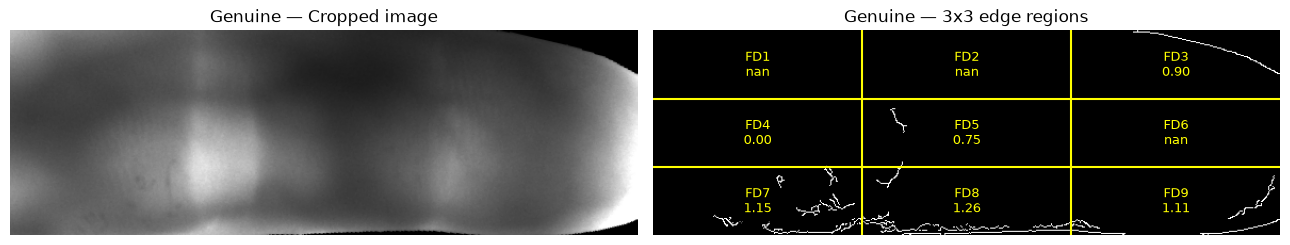

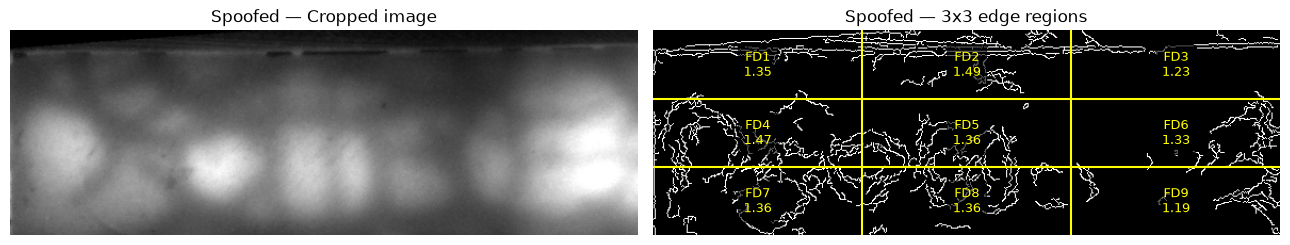

In [20]:
import matplotlib.pyplot as plt

def visualize_regions(image, title):
    height, width = image.shape

    cropped = image[
        :,
        int(width * 0.10):int(width * 0.90)
    ]

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(cropped)
    blurred = cv2.GaussianBlur(enhanced, (3, 3), 0)
    edges = cv2.Canny(blurred, 30, 100)

    features = extract_region_fractal_features(image)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].imshow(cropped, cmap="gray")
    axes[0].set_title(f"{title} — Cropped image")

    axes[1].imshow(edges, cmap="gray")
    axes[1].set_title(f"{title} — 3x3 edge regions")

    h, w = edges.shape

    for i in range(1, 3):
        axes[1].axhline(i * h / 3, color="yellow")
        axes[1].axvline(i * w / 3, color="yellow")

    for row in range(3):
        for col in range(3):
            feature_index = row * 3 + col
            fd = features[feature_index]

            axes[1].text(
                (col + 0.5) * w / 3,
                (row + 0.5) * h / 3,
                f"FD{feature_index+1}\n{fd:.2f}",
                color="yellow",
                fontsize=9,
                ha="center",
                va="center",
                bbox=dict(facecolor="black", alpha=0.6)
            )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_regions(real_image, "Genuine")
visualize_regions(spoof_image, "Spoofed")

## Approach 3: Regional Differential Box Counting (DBC)

For my third approach, I used Differential Box Counting (DBC).

Instead of converting the images into black-and-white patterns or detecting edges, DBC works directly with grayscale images and measures changes in pixel brightness across different scales.

I divided each image into nine regions using a 3×3 grid and calculated one Fractal Dimension value for each region.

This gave me a feature vector containing nine numbers for every image.

Why this approach worked better technically:

Unlike the previous edge-based method, DBC did not require visible edges in every region.

When I tested it on one genuine and one spoofed image, all nine Fractal Dimension values were calculated successfully, with no missing values.

It also allowed me to describe the image texture in different regions rather than relying on five fixed brightness thresholds.

Current limitation:

The method is working for my two test images, but I still need to apply it to the full dataset and evaluate the features using k-NN.

I also need to verify that the method captures meaningful finger-vein texture differences rather than only image brightness or other image artifacts.

In [21]:
import numpy as np
import cv2

def differential_box_counting(image):
    """
    Estimate grayscale fractal dimension using
    a simplified differential box-counting method.
    """

    image = image.astype(np.float64)

    height, width = image.shape
    min_side = min(height, width)

    box_sizes = [2, 4, 8, 16, 32]
    counts = []
    valid_sizes = []

    for size in box_sizes:

        if size > min_side:
            continue

        # Vertical gray-level box height
        gray_step = 256 * size / min_side

        total = 0

        for y in range(0, height - size + 1, size):
            for x in range(0, width - size + 1, size):

                block = image[y:y+size, x:x+size]

                minimum = block.min()
                maximum = block.max()

                # Number of intensity boxes occupied
                lower = np.floor(minimum / gray_step)
                upper = np.floor(maximum / gray_step)

                total += upper - lower + 1

        if total > 0:
            counts.append(total)
            valid_sizes.append(size)

    x = np.log(1 / np.array(valid_sizes))
    y = np.log(np.array(counts))

    dimension = np.polyfit(x, y, 1)[0]

    return dimension

## Create nine new feature-vector values

In [22]:
def extract_dbc_features(image):

    height, width = image.shape

    # Crop 10% from both sides
    cropped = image[
        :,
        int(width * 0.10):int(width * 0.90)
    ]

    # Enhance local contrast
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(cropped)

    # Divide into 3x3 regions
    features = []

    for row in np.array_split(enhanced, 3, axis=0):
        for region in np.array_split(row, 3, axis=1):

            fd = differential_box_counting(region)
            features.append(fd)

    return np.array(features, dtype=float)

## Test your two images

In [23]:
real_dbc = extract_dbc_features(real_image)
spoof_dbc = extract_dbc_features(spoof_image)

print("Genuine DBC feature vector:")
print(np.round(real_dbc, 4))

print("\nSpoofed DBC feature vector:")
print(np.round(spoof_dbc, 4))

print("\nVector lengths:")
print(len(real_dbc), len(spoof_dbc))

print("\nAll values valid?")
print(
    np.isfinite(real_dbc).all(),
    np.isfinite(spoof_dbc).all()
)

Genuine DBC feature vector:
[2.0602 2.1036 2.1074 2.059  2.1097 2.0627 2.0827 2.1062 2.0888]

Spoofed DBC feature vector:
[2.089  2.1309 2.133  2.0913 2.0892 2.1348 2.075  2.0892 2.0782]

Vector lengths:
9 9

All values valid?
True True


## Visualization 1 — Show the nine image regions

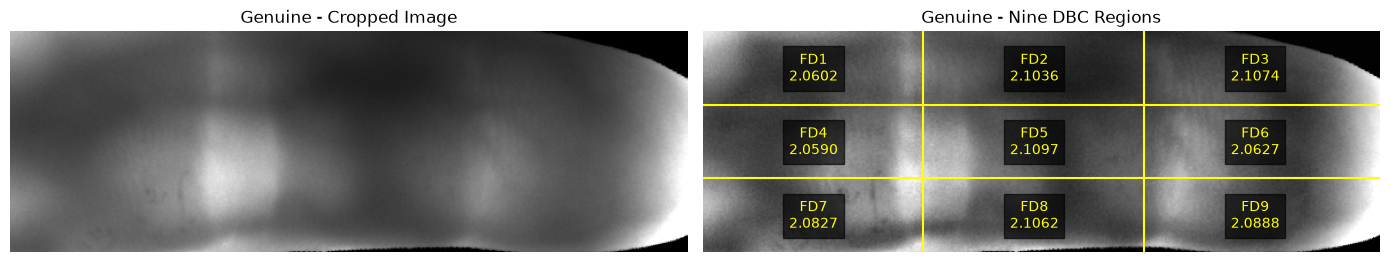

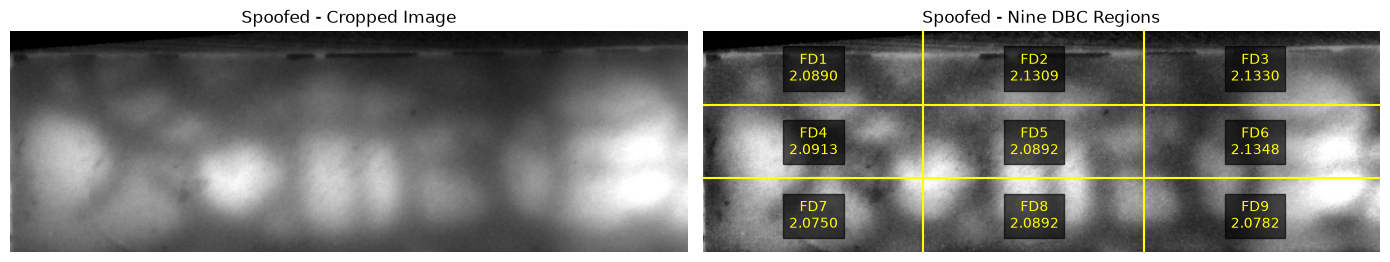

In [24]:
import numpy as np
import matplotlib.pyplot as plt

def visualize_dbc_regions(image, title):
    height, width = image.shape

    # Same cropping used in DBC feature extraction
    cropped = image[:, int(width * 0.10):int(width * 0.90)]

    # Same contrast enhancement
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    enhanced = clahe.apply(cropped)

    # Get the nine DBC feature values
    features = extract_dbc_features(image)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Original image
    axes[0].imshow(cropped, cmap="gray")
    axes[0].set_title(f"{title} - Cropped Image")
    axes[0].axis("off")

    # Enhanced image divided into nine regions
    axes[1].imshow(enhanced, cmap="gray")
    axes[1].set_title(f"{title} - Nine DBC Regions")

    h, w = enhanced.shape

    # Exact boundaries used by np.array_split
    row_bounds = np.cumsum([0] + [
        len(r) for r in np.array_split(enhanced, 3, axis=0)
    ])

    col_bounds = np.cumsum([0] + [
        len(c) for c in np.array_split(enhanced, 3, axis=1)
    ])

    for boundary in row_bounds[1:-1]:
        axes[1].axhline(boundary - 0.5, color="yellow", linewidth=1.5)

    for boundary in col_bounds[1:-1]:
        axes[1].axvline(boundary - 0.5, color="yellow", linewidth=1.5)

    # Display DBC value inside each region
    for row in range(3):
        for col in range(3):
            idx = row * 3 + col

            x = (col_bounds[col] + col_bounds[col + 1]) / 2
            y = (row_bounds[row] + row_bounds[row + 1]) / 2

            axes[1].text(
                x, y,
                f"FD{idx+1}\n{features[idx]:.4f}",
                color="yellow",
                ha="center",
                va="center",
                fontsize=10,
                bbox=dict(facecolor="black", alpha=0.65)
            )

    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


visualize_dbc_regions(real_image, "Genuine")
visualize_dbc_regions(spoof_image, "Spoofed")

## How do my feature vectors look?
Each finger-vein image is represented by a feature vector containing **nine Fractal Dimension values**.

I divide the image into a 3×3 grid, giving me nine regions. For each region, I calculate its Fractal Dimension using Differential Box Counting (DBC).

For example, the feature vector of one genuine image is:

[2.0602, 2.1036, 2.1074, 2.0590, 2.1097, 2.0627, 2.0827, 2.1062, 2.0888]

Each number represents the estimated texture complexity of one region.

Every feature vector has a separate label:
- **0 = Genuine**
- **1 = Spoofed**

I extracted nine features for each of the 786 selected images, so my feature matrix has a shape of **786 × 9**.

## Visualization 2 — Compare genuine and spoofed feature vectors

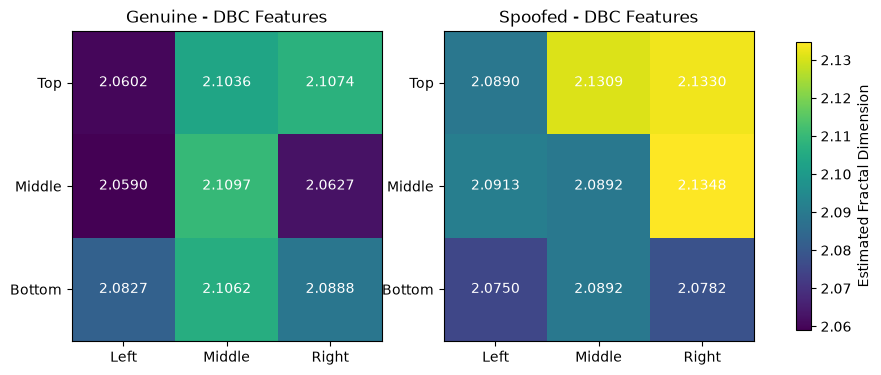

In [25]:
import matplotlib.pyplot as plt
import numpy as np

# Already calculated in your previous step
real_dbc = extract_dbc_features(real_image)
spoof_dbc = extract_dbc_features(spoof_image)

# Convert the nine values into 3x3 matrices
real_grid = real_dbc.reshape(3, 3)
spoof_grid = spoof_dbc.reshape(3, 3)

# Use the same color scale for fair comparison
vmin = min(real_dbc.min(), spoof_dbc.min())
vmax = max(real_dbc.max(), spoof_dbc.max())

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, data, title in zip(
    axes,
    [real_grid, spoof_grid],
    ["Genuine - DBC Features", "Spoofed - DBC Features"]
):
    im = ax.imshow(data, cmap="viridis", vmin=vmin, vmax=vmax)

    ax.set_title(title)
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(["Left", "Middle", "Right"])
    ax.set_yticklabels(["Top", "Middle", "Bottom"])

    for row in range(3):
        for col in range(3):
            ax.text(
                col, row,
                f"{data[row, col]:.4f}",
                ha="center",
                va="center",
                color="white",
                fontsize=10
            )

fig.colorbar(im, ax=axes, shrink=0.75, label="Estimated Fractal Dimension")

plt.show()

## Visualization 3 — Compare all nine features in one graph

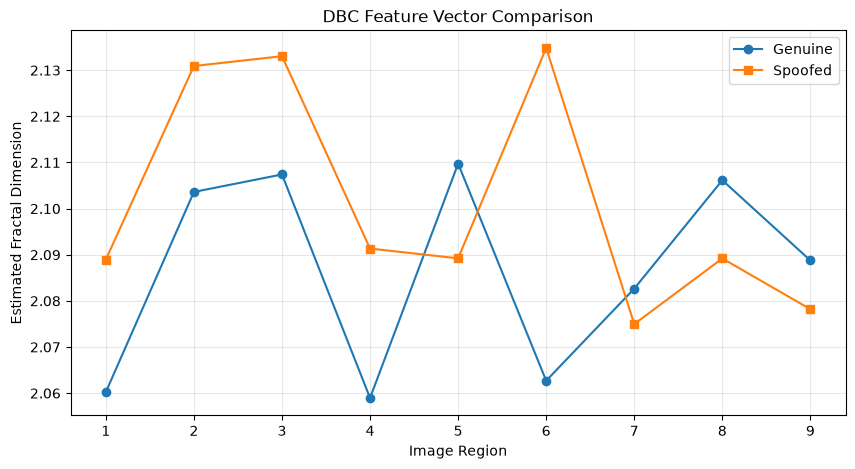

In [26]:
regions = np.arange(1, 10)

plt.figure(figsize=(10, 5))

plt.plot(
    regions, real_dbc,
    marker="o",
    label="Genuine"
)

plt.plot(
    regions, spoof_dbc,
    marker="s",
    label="Spoofed"
)

plt.xticks(regions)
plt.xlabel("Image Region")
plt.ylabel("Estimated Fractal Dimension")
plt.title("DBC Feature Vector Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 9- Extract DBC Features for the Complete PLUS Dataset

After testing Differential Box Counting on one genuine and one spoofed image,
I will now use the same method to extract features from all selected images.

Each image will have:
- Nine Fractal Dimension features (FD1 to FD9)
- A label: 0 for genuine and 1 for spoofed
- A subject ID to keep subjects separate during testing

These features will later be used to train the k-NN classifier.

In [27]:
import numpy as np
import pandas as pd
import cv2
from time import perf_counter

feature_records = []
start_time = perf_counter()

for index, row in dataset_df.iterrows():

    # Load the image
    image = cv2.imread(
        str(row["path"]),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError(f"Cannot load image: {row['path']}")

    # Extract nine DBC features
    features = extract_dbc_features(image)

    # Check the feature vector
    if len(features) != 9 or not np.isfinite(features).all():
        raise ValueError(f"Invalid features: {row['path']}")

    # Save image information
    record = {
        "subject_id": str(row["subject_id"]).zfill(3),
        "image_path": row["path"],
        "label": int(row["label"])
    }

    # Store the nine features
    for i, value in enumerate(features, start=1):
        record[f"FD{i}"] = float(value)

    feature_records.append(record)

    if len(feature_records) % 100 == 0:
        print(
            f"Processed {len(feature_records)}/{len(dataset_df)} images"
        )

dbc_df = pd.DataFrame(feature_records)

print("\nFeature extraction completed!")
print("Total images:", len(dbc_df))
print("Unique subjects:", dbc_df["subject_id"].nunique())
print("Time taken:", round(perf_counter() - start_time, 2), "seconds")

display(dbc_df.head())

Processed 100/786 images
Processed 200/786 images
Processed 300/786 images
Processed 400/786 images
Processed 500/786 images
Processed 600/786 images
Processed 700/786 images

Feature extraction completed!
Total images: 786
Unique subjects: 22
Time taken: 99.33 seconds


,subject_id,image_path,label,FD1,FD2,FD3,FD4,FD5,FD6,FD7,FD8,FD9
0,001,Data_FV_Spoofing_WS2025_26/PLUS/real/001/PLUS-...,0,2.060246,2.103616,2.107409,2.058954,2.109745,2.062698,2.082660,2.106161,2.088765
1,001,Data_FV_Spoofing_WS2025_26/PLUS/spoof/001/PLUS...,1,2.088964,2.130912,2.133041,2.091342,2.089225,2.134818,2.074973,2.089201,2.078200
2,001,Data_FV_Spoofing_WS2025_26/PLUS/real/001/PLUS-...,0,2.057020,2.149925,2.123309,2.076006,2.115287,2.069607,2.068334,2.094468,2.106973
3,001,Data_FV_Spoofing_WS2025_26/PLUS/spoof/001/PLUS...,1,2.108141,2.149748,2.112489,2.079604,2.069463,2.072058,2.107958,2.074806,2.102451
4,001,Data_FV_Spoofing_WS2025_26/PLUS/real/001/PLUS-...,0,2.071258,2.152026,2.115700,2.088034,2.102701,2.045369,2.062806,2.111535,2.078390


## Save the features to CSV

In [28]:
dbc_df.to_csv("PLUS_DBC_features.csv", index=False)

print("Feature vectors saved successfully!")

Feature vectors saved successfully!


## Check your feature data

In [29]:
feature_columns = [f"FD{i}" for i in range(1, 10)]

print("Class distribution:")
print(dbc_df["label"].value_counts())

print("\nAll features valid?")
print(np.isfinite(dbc_df[feature_columns].to_numpy()).all())

print("\nNumber of features per image:")
print(len(feature_columns))

print("\nFeature matrix shape:")
print(dbc_df[feature_columns].shape)

Class distribution:
label
0    393
1    393
Name: count, dtype: int64

All features valid?
True

Number of features per image:
9

Feature matrix shape:
(786, 9)


## Prepare feature vectors and labels for k-NN
The DBC algorithm converted every image into nine numerical features.

X contains the feature vectors.
y contains the genuine/spoofed labels.
groups contains the subject IDs.

The subject IDs are needed to ensure that the classifier is tested
on people who were not included in the training data.

In [30]:
X = dbc_df[feature_columns].to_numpy(dtype=float)

y = dbc_df["label"].to_numpy(dtype=int)

groups = dbc_df["subject_id"].to_numpy()

print("Feature matrix X:", X.shape)
print("Labels y:", y.shape)
print("Subject groups:", groups.shape)

print("\nFirst image feature vector:")
print(X[0])

print("\nIts label:")
print(y[0])

Feature matrix X: (786, 9)
Labels y: (786,)
Subject groups: (786,)

First image feature vector:
[2.06024585 2.10361568 2.10740852 2.05895395 2.1097452  2.06269831
 2.08265982 2.10616084 2.08876512]

Its label:
0


## Five-Fold Cross-Validation
I divided the dataset into five folds based on subject IDs. Images belonging to the same person must remain together so that the classifier is tested on subjects it has not seen during training. For the baseline experiment, four folds are used for training and one fold for testing. This is repeated five times.



In [31]:
from sklearn.model_selection import GroupKFold
import numpy as np

# Divide data into 5 folds, keeping subjects together
cv = GroupKFold(n_splits=5)

folds = list(cv.split(X, y, groups))

for fold_number, (train_idx, test_idx) in enumerate(folds, 1):

    train_subjects = set(groups[train_idx])
    test_subjects = set(groups[test_idx])

    # Check that subjects do not overlap
    assert train_subjects.isdisjoint(test_subjects)

    print(f"\nFold {fold_number}")
    print("Training subjects:", len(train_subjects))
    print("Testing subjects:", len(test_subjects))
    print("Training images:", len(train_idx))
    print("Testing images:", len(test_idx))
    print("Subject overlap:", len(train_subjects & test_subjects))


Fold 1
Training subjects: 17
Testing subjects: 5
Training images: 606
Testing images: 180
Subject overlap: 0

Fold 2
Training subjects: 17
Testing subjects: 5
Training images: 612
Testing images: 174
Subject overlap: 0

Fold 3
Training subjects: 18
Testing subjects: 4
Training images: 642
Testing images: 144
Subject overlap: 0

Fold 4
Training subjects: 18
Testing subjects: 4
Training images: 642
Testing images: 144
Subject overlap: 0

Fold 5
Training subjects: 18
Testing subjects: 4
Training images: 642
Testing images: 144
Subject overlap: 0


## k-Nearest Neighbors Classification
Each image is represented by nine Differential Box Counting features. The k-NN classifier compares the feature vector of an unknown test image with the labeled training vectors. With k = 3, it finds the three closest training examples and predicts the majority label.

In [32]:
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

baseline_results = []

for fold_number, (train_idx, test_idx) in enumerate(folds, 1):

    # Training data
    X_train = X[train_idx]
    y_train = y[train_idx]

    # Testing data
    X_test = X[test_idx]
    y_test = y[test_idx]

    # Scale features and create k-NN classifier
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)
    )

    # Train using labeled feature vectors
    model.fit(X_train, y_train)

    # Predict labels of unseen test images
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    apcer = np.mean(predictions[y_test == 1] == 0)
    bpcer = np.mean(predictions[y_test == 0] == 1)
    acer = (apcer + bpcer) / 2

    baseline_results.append({
        "Fold": fold_number,
        "Training images": len(train_idx),
        "Testing images": len(test_idx),
        "APCER (%)": apcer * 100,
        "BPCER (%)": bpcer * 100,
        "ACER (%)": acer * 100
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df)

print("\nMean results:")
display(
    baseline_df[
        ["APCER (%)", "BPCER (%)", "ACER (%)"]
    ].mean().round(2)
)

,Fold,Training images,Testing images,APCER (%),BPCER (%),ACER (%)
0,1,606,180,7.777778,22.222222,15.000000
1,2,612,174,6.896552,20.689655,13.793103
2,3,642,144,1.388889,23.611111,12.500000
3,4,642,144,5.555556,23.611111,14.583333
4,5,642,144,2.777778,5.555556,4.166667



Mean results:


APCER (%)     4.88
BPCER (%)    19.14
ACER (%)     12.01
dtype: float64

## Show the three nearest neighbors

In [33]:
# Use the first cross-validation fold
train_idx, test_idx = folds[0]

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

model.fit(X[train_idx], y[train_idx])

# Choose one test image
test_image = X[test_idx[0]].reshape(1, -1)

# Apply training-set scaling
scaled_test = model.named_steps[
    "standardscaler"
].transform(test_image)

# Get the actual k-NN classifier
knn = model.named_steps["kneighborsclassifier"]

# Find three nearest training examples
distances, neighbor_indices = knn.kneighbors(
    scaled_test,
    n_neighbors=3
)

print("Three nearest neighbors:\n")

for rank, (distance, index) in enumerate(
    zip(distances[0], neighbor_indices[0]), 1
):
    original_index = train_idx[index]

    label = y[original_index]
    label_name = "Genuine" if label == 0 else "Spoofed"

    print(
        f"Neighbor {rank}: "
        f"{label_name} (Label {label}), "
        f"Distance = {distance:.4f}"
    )

predicted = model.predict(test_image)[0]
actual = y[test_idx[0]]

print("\nPredicted:",
      "Genuine" if predicted == 0 else "Spoofed")

print("Actual:",
      "Genuine" if actual == 0 else "Spoofed")

Three nearest neighbors:

Neighbor 1: Genuine (Label 0), Distance = 1.2485
Neighbor 2: Genuine (Label 0), Distance = 1.5124
Neighbor 3: Genuine (Label 0), Distance = 1.6361

Predicted: Genuine
Actual: Genuine


## How I Created Feature Vectors for k-NN Classification

I used **Regional Differential Box Counting (DBC)** to create feature vectors from the finger-vein images.

### Feature Extraction Process

1. **Load the image:** I load each finger-vein image in grayscale.
2. **Crop the image:** I remove approximately 10% from each horizontal side to reduce border interference.
3. **Enhance the contrast:** I apply CLAHE to improve the visibility of image details.
4. **Divide into regions:** I divide the processed image into a 3×3 grid, creating nine regions.
5. **Calculate Fractal Dimension:** I use my Differential Box Counting implementation to calculate one Fractal Dimension estimate for each region.
6. **Create the feature vector:** I combine the nine calculated values into a single feature vector.

I repeat this process for all **786 selected PLUS images**, including 393 genuine and 393 spoofed images.

### Feature Matrix and Labels

Each image produces nine numerical features.

For example, one genuine image produced:

`[2.0602, 2.1036, 2.1074, 2.0590, 2.1097, 2.0627, 2.0827, 2.1062, 2.0888]`

The complete dataset contains:

- **Feature matrix X:** (786, 9)
- **Labels y:** (786,)
- **Subject IDs:** (786,)

The class labels are:

- **0 = Genuine**
- **1 = Spoofed**

### Applying the Feature Vectors to k-NN

I use a k-Nearest Neighbors classifier with **k = 3**.

First, I standardize the features using `StandardScaler`, fitted only on the training data.

For each test image, k-NN compares its nine-dimensional feature vector with the training feature vectors and finds the three closest training examples.

The classifier predicts the class that appears most frequently among these three neighbors.

---

## Baseline Evaluation — Five-Fold Cross-Validation

I evaluated the regional DBC features using five-fold subject-disjoint cross-validation.

In each fold, I trained the classifier using four groups of subjects and tested it on the remaining group.

I ensured that no subject appeared in both the training and testing sets within the same fold.

### Baseline Results

| Metric | Mean result |
|---|---:|
| APCER | 4.88% |
| BPCER | 19.14% |
| ACER | 12.01% |

These values are the unweighted averages of the five fold-wise error rates.

### My Observations

**1. Subject Separation**

There was no overlap between training and testing subjects in any of the five folds. Therefore, the classifier was evaluated using images from subjects that were not included in training.

**2. Classification Performance**

The average ACER was **12.01%**, indicating that the classifier made classification errors when distinguishing genuine and spoofed images.

**3. Spoofed Image Classification**

The average APCER was **4.88%**. This means that relatively few spoofed images were incorrectly classified as genuine.

**4. Genuine Image Classification**

The average BPCER was **19.14%**, considerably higher than APCER.

This indicates that the classifier had more difficulty correctly identifying genuine images than spoofed images.

**5. Differences Between Folds**

The classification results varied across the five folds.

- **Best result:** Fold 5, with ACER = 4.17%.
- **Highest error:** Fold 1, with ACER = 15.00%.

This suggests that the classifier's performance depends partly on which subjects are used for testing.

### Conclusion

The regional DBC implementation successfully generated nine finite feature values for every selected image, and these features could be used with k-NN for classification.

However, the classifier incorrectly rejects a relatively high proportion of genuine images.

The results are preliminary because the simplified DBC calculation still needs mathematical validation. I also need to investigate whether the features capture meaningful finger-vein texture or are influenced by brightness and other image characteristics.

My next step is to evaluate the classifier using smaller real training sets (2/5 and 1/5), while keeping the same held-out test folds.

In [34]:
import pandas as pd

# Use first cross-validation fold
train_idx, test_idx = folds[0]

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

model.fit(X[train_idx], y[train_idx])

# Select one held-out test image
test_index = test_idx[0]
test_image = X[test_index].reshape(1, -1)

# Apply the scaler fitted on training data
scaled_test = model.named_steps[
    "standardscaler"
].transform(test_image)

knn = model.named_steps["kneighborsclassifier"]

distances, neighbor_indices = knn.kneighbors(
    scaled_test,
    n_neighbors=3
)

records = []

for rank, (distance, neighbor_index) in enumerate(
    zip(distances[0], neighbor_indices[0]), start=1
):
    original_index = train_idx[neighbor_index]

    records.append({
        "Test Image": dbc_df.iloc[test_index]["image_path"],
        "Test Actual Label": int(y[test_index]),
        "Neighbor Rank": rank,
        "Neighbor Image": dbc_df.iloc[original_index]["image_path"],
        "Neighbor Label": int(y[original_index]),
        "Distance": float(distance)
    })

neighbors_df = pd.DataFrame(records)

display(neighbors_df)

neighbors_df.to_csv(
    "PLUS_3_nearest_neighbors.csv",
    index=False
)

print("Three nearest neighbors saved!")

,Test Image,Test Actual Label,Neighbor Rank,Neighbor Image,Neighbor Label,Distance
0,Data_FV_Spoofing_WS2025_26/PLUS/real/001/PLUS-...,0,1,Data_FV_Spoofing_WS2025_26/PLUS/real/057/PLUS-...,0,1.248486
1,Data_FV_Spoofing_WS2025_26/PLUS/real/001/PLUS-...,0,2,Data_FV_Spoofing_WS2025_26/PLUS/real/009/PLUS-...,0,1.512375
2,Data_FV_Spoofing_WS2025_26/PLUS/real/001/PLUS-...,0,3,Data_FV_Spoofing_WS2025_26/PLUS/real/002/PLUS-...,0,1.636052


Three nearest neighbors saved!
